# ENGE707 Kaggle Competition: Final Prediction and Submission

## Cat and Dog Facial Feature Classification

This notebook uses the **selected ResNet18 model** from Notebook 5 to predict the class of every unseen Kaggle test image. It preserves the order of `sample_submission.csv`, validates the completed submission, and saves evidence for the report.

The test images are used only for final prediction. They are not used to train the model, choose hyperparameters, or select between models.

## 1. Import the Required Libraries

These libraries support file handling, image preprocessing, PyTorch inference, tables, and figures. No training tools or random augmentation are required because the final model has already been selected and trained.

In [5]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile
import json
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

from IPython.display import FileLink, display

## 2. Locate the Project Files

Kaggle stores attached inputs in read-only folders under `/kaggle/input`. This cell finds the competition data, preprocessing configuration, selected-model record, and trained ResNet18 checkpoint without relying on a specific Kaggle dataset name. When run locally, it uses the normal project folders.

In [6]:
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_kaggle_input_file(filename, required=True):
    """Find one named file among all attached Kaggle inputs."""
    matches = sorted(Path("/kaggle/input").rglob(filename))

    if matches:
        return matches[0]

    if required:
        raise FileNotFoundError(
            f"Kaggle input file not found: {filename}. "
            "Attach the competition data and project artifacts."
        )

    return None


def find_kaggle_test_directory(filename):
    """Find the test folder containing one known test image."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    test_matches = [
        path for path in matches
        if "test" in {part.lower() for part in path.parent.parts}
    ]

    if not test_matches:
        raise FileNotFoundError(
            f"Could not locate the test folder containing {filename}."
        )

    return test_matches[0].parent


if RUNNING_ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")
    SAMPLE_SUBMISSION_PATH = find_kaggle_input_file(
        "sample_submission.csv"
    )
    PREPROCESSING_CONFIG_PATH = find_kaggle_input_file(
        "preprocessing_config.json"
    )
    SELECTED_MODEL_PATH = find_kaggle_input_file(
        "selected_model.json",
        required=False,
    )

    if SELECTED_MODEL_PATH is None:
        evaluation_zip = find_kaggle_input_file(
            "model_evaluation_results.zip",
            required=False,
        )

        if evaluation_zip is not None:
            extraction_dir = (
                PROJECT_ROOT / "attached_evaluation"
            )
            extraction_dir.mkdir(
                parents=True,
                exist_ok=True,
            )

            with ZipFile(evaluation_zip) as archive:
                selected_members = [
                    member for member in archive.namelist()
                    if Path(member).name == "selected_model.json"
                ]

                if selected_members:
                    SELECTED_MODEL_PATH = Path(
                        archive.extract(
                            selected_members[0],
                            extraction_dir,
                        )
                    )

    CHECKPOINT_PATH = find_kaggle_input_file(
        "resnet18_best.pth"
    )

    submission_probe = pd.read_csv(
        SAMPLE_SUBMISSION_PATH,
        dtype={"image_id": "string"},
        nrows=1,
    )
    probe_id = int(submission_probe.iloc[0]["image_id"])
    TEST_IMAGE_DIR = find_kaggle_test_directory(
        f"{probe_id:05d}.jpg"
    )
else:
    possible_roots = [Path.cwd(), Path.cwd().parent]
    PROJECT_ROOT = next(
        (
            folder for folder in possible_roots
            if (folder / "data" / "sample_submission.csv").exists()
        ),
        None,
    )

    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "The local project folder could not be found."
        )

    SAMPLE_SUBMISSION_PATH = (
        PROJECT_ROOT / "data" / "sample_submission.csv"
    )
    PREPROCESSING_CONFIG_PATH = (
        PROJECT_ROOT / "outputs" / "preprocessing"
        / "preprocessing_config.json"
    )
    SELECTED_MODEL_PATH = (
        PROJECT_ROOT / "outputs" / "evaluation"
        / "selected_model.json"
    )
    CHECKPOINT_PATH = PROJECT_ROOT / "models" / "resnet18_best.pth"
    TEST_IMAGE_DIR = PROJECT_ROOT / "data" / "test" / "test"

SUBMISSION_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "submission"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
SUBMISSION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FINAL_SUBMISSION_PATH = SUBMISSION_OUTPUT_DIR / "submission.csv"
PREDICTION_DETAILS_PATH = (
    SUBMISSION_OUTPUT_DIR / "test_prediction_details.csv"
)
SUBMISSION_CHECKS_PATH = (
    SUBMISSION_OUTPUT_DIR / "submission_checks.csv"
)
SUBMISSION_SUMMARY_PATH = (
    SUBMISSION_OUTPUT_DIR / "submission_summary.json"
)
CLASS_DISTRIBUTION_FIGURE_PATH = (
    FIGURE_DIR / "figure_20_test_prediction_distribution.png"
)
CONFIDENCE_FIGURE_PATH = (
    FIGURE_DIR / "figure_21_test_prediction_confidence.png"
)
RESULTS_ZIP_PATH = PROJECT_ROOT / "kaggle_submission_results.zip"

print("Environment:", "Kaggle" if RUNNING_ON_KAGGLE else "Local")
print("Test images:", TEST_IMAGE_DIR)
print("Selected checkpoint:", CHECKPOINT_PATH)
print("Submission template:", SAMPLE_SUBMISSION_PATH)

Environment: Kaggle
Test images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/test/test
Selected checkpoint: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/resnet18_best.pth
Submission template: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/sample_submission.csv


## 3. Load and Verify the Saved Configuration

The class order and preprocessing values must match those used during training. Notebook 5 selected ResNet18 using only labelled validation results, so this notebook verifies that decision before test prediction begins.

In [7]:
with open(PREPROCESSING_CONFIG_PATH) as config_file:
    preprocessing_config = json.load(config_file)

if SELECTED_MODEL_PATH is not None:
    with open(SELECTED_MODEL_PATH) as selected_file:
        selected_model = json.load(selected_file)
else:
    selected_model = {
        "selected_model": "ResNet18",
        "selection_basis": (
            "Highest validation accuracy, followed by macro F1 "
            "and lower validation loss"
        ),
        "validation_accuracy": 0.9965441407477222,
        "validation_loss": 0.05813228863048883,
        "macro_f1": 0.9967091701795414,
        "validation_images": 12732,
        "test_images_used_for_selection": False,
        "source": "Verified Notebook 5 evaluation output",
    }

sample_submission = pd.read_csv(
    SAMPLE_SUBMISSION_PATH,
    dtype={"image_id": "string", "class": "string"},
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
IMAGENET_MEAN = preprocessing_config["normalisation_mean"]
IMAGENET_STD = preprocessing_config["normalisation_std"]
NUMBER_OF_CLASSES = len(CLASS_NAMES)

if selected_model["selected_model"] != "ResNet18":
    raise ValueError(
        "Notebook 5 did not select ResNet18. Review selected_model.json."
    )

print("Selected model:", selected_model["selected_model"])
print("Validation accuracy:", f"{selected_model['validation_accuracy']:.2%}")
print("Test rows required:", f"{len(sample_submission):,}")
print("Official classes:", CLASS_NAMES)

Selected model: ResNet18
Validation accuracy: 99.65%
Test rows required: 29,443
Official classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']


## 4. Create the Deterministic Test Transform

Each test image is converted to RGB, padded to a square, resized to 224 × 224 pixels, converted to a PyTorch tensor, and normalised using the same ImageNet values used during training. Random augmentation is not applied because each test image needs one stable final prediction.

In [8]:
class SquarePad:
    """Pad the shorter sides without stretching the image."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        largest_side = max(width, height)
        horizontal_padding = largest_side - width
        vertical_padding = largest_side - height

        left = horizontal_padding // 2
        right = horizontal_padding - left
        top = vertical_padding // 2
        bottom = vertical_padding - top

        return ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill=self.fill,
        )


test_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

print(test_transform)
assert "Random" not in repr(test_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 5. Build the Test Dataset and Data Loader

The dataset follows the exact row order of `sample_submission.csv`. A five-digit filename is created from each `image_id`, such as ID `1` becoming `00001.jpg`. The data loader does not shuffle the images, which protects the required submission order.

In [9]:
class TestImageDataset(Dataset):
    """Load test images in sample-submission order."""

    def __init__(self, dataframe, image_directory, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_id = self.dataframe.iloc[index]["image_id"]
        filename = f"{int(image_id):05d}.jpg"
        image_path = self.image_directory / filename

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return {"image": image, "image_id": str(image_id)}


BATCH_SIZE = 256 if torch.cuda.is_available() else 32
NUM_WORKERS = 2 if RUNNING_ON_KAGGLE else 0
PIN_MEMORY = torch.cuda.is_available()

test_dataset = TestImageDataset(
    sample_submission,
    TEST_IMAGE_DIR,
    test_transform,
)

loader_options = {}
if NUM_WORKERS > 0:
    loader_options = {
        "persistent_workers": True,
        "prefetch_factor": 2,
    }

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_options,
)

print("Test images loaded:", f"{len(test_dataset):,}")
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)

Test images loaded: 29,443
Test batches: 116
Batch size: 256


## 6. Rebuild and Load the Selected ResNet18 Model

The final classification layer returns eight scores, one for each official class. The saved checkpoint restores the weights from the best validation epoch rather than the final training epoch.

In [10]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

final_model = models.resnet18(weights=None)
final_model.fc = nn.Linear(
    final_model.fc.in_features,
    NUMBER_OF_CLASSES,
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_classes = list(checkpoint["class_names"])
if checkpoint_classes != CLASS_NAMES:
    raise ValueError(
        "The checkpoint class order does not match preprocessing_config.json."
    )

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model = final_model.to(DEVICE)
final_model.eval()

print("Device:", DEVICE)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation accuracy:", f"{checkpoint['validation_accuracy']:.2%}")
print("Output classes:", final_model.fc.out_features)

Device: cuda
Checkpoint epoch: 10
Checkpoint validation accuracy: 99.65%
Output classes: 8


## 7. Generate Test Predictions

Inference mode disables gradient calculation because model weights are not being updated. Softmax converts the eight output scores into probabilities. The class with the highest probability becomes the final prediction, while confidence is retained only as supporting evidence and is not included in the Kaggle CSV.

In [11]:
prediction_rows = []
prediction_start = time.perf_counter()

with torch.inference_mode():
    for batch in test_loader:
        images = batch["image"].to(
            DEVICE,
            non_blocking=DEVICE.type == "cuda",
        )
        logits = final_model(images)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predicted_indices = probabilities.max(dim=1)

        for image_id, class_index, probability in zip(
            batch["image_id"],
            predicted_indices.cpu().tolist(),
            confidence.cpu().tolist(),
        ):
            prediction_rows.append(
                {
                    "image_id": str(image_id),
                    "predicted_class": INDEX_TO_CLASS[class_index],
                    "confidence": probability,
                }
            )

prediction_seconds = time.perf_counter() - prediction_start
prediction_details = pd.DataFrame(prediction_rows)

print("Predictions generated:", f"{len(prediction_details):,}")
print("Prediction time:", f"{prediction_seconds / 60:.2f} minutes")
display(prediction_details.head(10))

Predictions generated: 29,443
Prediction time: 25.09 minutes


,image_id,predicted_class,confidence
0,1,DogEye,0.938233
1,2,DogMouth,0.962239
2,3,DogNose,0.983713
3,4,DogFace,0.932374
4,5,CatMouth,0.979950
5,6,DogFace,0.967499
6,7,CatMouth,0.973145
7,8,CatEye,0.659764
8,9,CatEye,0.914351
9,10,CatNose,0.940037


## 8. Create and Validate the Kaggle Submission

Only the required `image_id` and `class` columns are written to the submission file. The checks confirm that every test row appears exactly once, the original order is unchanged, no prediction is missing, and every label uses an official class name with exact spelling and capitalisation.

In [12]:
submission = sample_submission[["image_id"]].copy()
submission["class"] = prediction_details["predicted_class"].values

submission_checks = pd.DataFrame(
    {
        "check": [
            "Columns are exactly image_id and class",
            "Row count matches sample submission",
            "Image ID order is unchanged",
            "Every image ID is unique",
            "No prediction is missing",
            "Every prediction is an official class",
            "Every test image received one prediction",
            "Test transform has no random augmentation",
            "Notebook 5 selected ResNet18",
        ],
        "result": [
            list(submission.columns) == ["image_id", "class"],
            len(submission) == len(sample_submission),
            submission["image_id"].equals(
                sample_submission["image_id"]
            ),
            submission["image_id"].is_unique,
            not submission["class"].isna().any(),
            set(submission["class"]).issubset(set(CLASS_NAMES)),
            len(prediction_details) == len(test_dataset),
            "Random" not in repr(test_transform),
            selected_model["selected_model"] == "ResNet18",
        ],
        "expected": [True] * 9,
    }
)

submission.to_csv(FINAL_SUBMISSION_PATH, index=False)
prediction_details.to_csv(PREDICTION_DETAILS_PATH, index=False)
submission_checks.to_csv(SUBMISSION_CHECKS_PATH, index=False)

display(submission_checks)
display(submission.head(10))
assert submission_checks["result"].all()

print("Validated Kaggle submission:", FINAL_SUBMISSION_PATH)

,check,result,expected
0,Columns are exactly image_id and class,True,True
1,Row count matches sample submission,True,True
2,Image ID order is unchanged,True,True
3,Every image ID is unique,True,True
4,No prediction is missing,True,True
5,Every prediction is an official class,True,True
6,Every test image received one prediction,True,True
7,Test transform has no random augmentation,True,True
8,Notebook 5 selected ResNet18,True,True


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth
5,6,DogFace
6,7,CatMouth
7,8,CatEye
8,9,CatEye
9,10,CatNose


Validated Kaggle submission: /kaggle/working/outputs/submission/submission.csv


## 9. Save Prediction Evidence for the Report

The first figure shows how often each class was predicted in the hidden test set. The second shows the model's prediction confidence. These plots describe the final output only; they are not used to change the model or tune its settings.

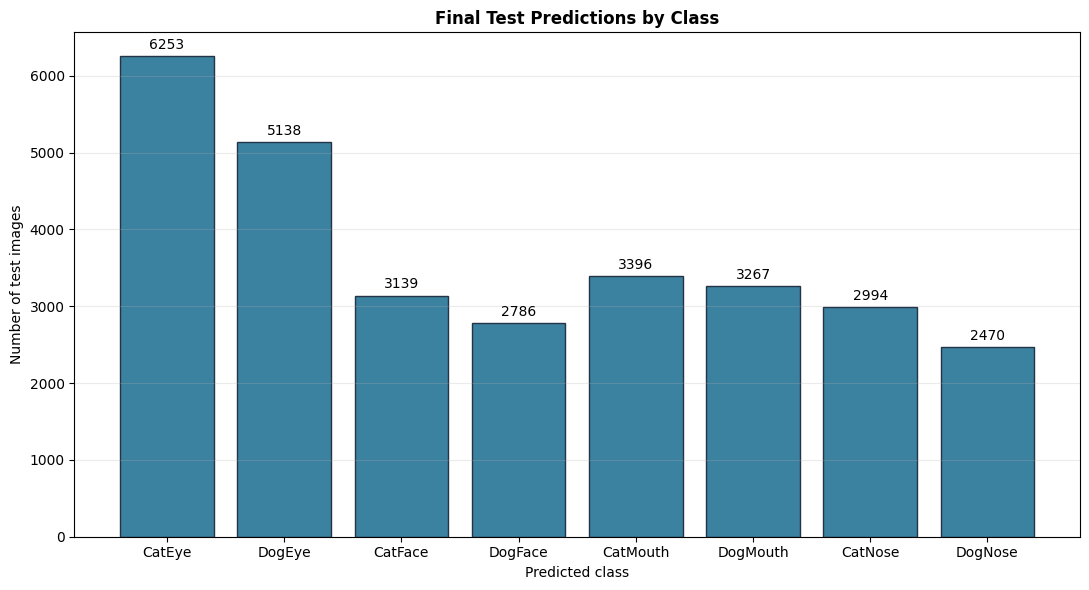

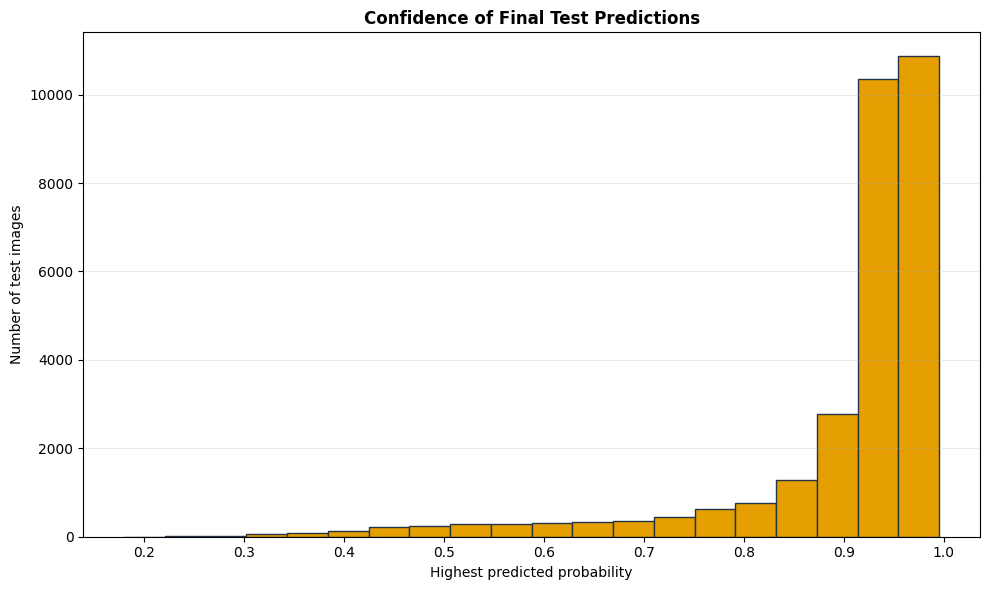

,class,predictions,percentage
0,CatEye,6253,21.24
1,DogEye,5138,17.45
2,CatFace,3139,10.66
3,DogFace,2786,9.46
4,CatMouth,3396,11.53
5,DogMouth,3267,11.10
6,CatNose,2994,10.17
7,DogNose,2470,8.39


Submission summary: /kaggle/working/outputs/submission/submission_summary.json
Figures saved: /kaggle/working/outputs/figures/figure_20_test_prediction_distribution.png
                /kaggle/working/outputs/figures/figure_21_test_prediction_confidence.png


In [13]:
predicted_counts = (
    submission["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(
    predicted_counts.index,
    predicted_counts.values,
    color="#3B82A0",
    edgecolor="#243447",
)
ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_title("Final Test Predictions by Class", weight="bold")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Number of test images")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    CLASS_DISTRIBUTION_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    prediction_details["confidence"],
    bins=20,
    color="#E69F00",
    edgecolor="#243447",
)
ax.set_title("Confidence of Final Test Predictions", weight="bold")
ax.set_xlabel("Highest predicted probability")
ax.set_ylabel("Number of test images")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    CONFIDENCE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

submission_summary = {
    "selected_model": selected_model["selected_model"],
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "validation_accuracy": float(
        selected_model["validation_accuracy"]
    ),
    "test_images": int(len(submission)),
    "prediction_seconds": float(prediction_seconds),
    "mean_confidence": float(
        prediction_details["confidence"].mean()
    ),
    "minimum_confidence": float(
        prediction_details["confidence"].min()
    ),
    "predicted_class_counts": {
        class_name: int(count)
        for class_name, count in predicted_counts.items()
    },
    "submission_checks_passed": bool(
        submission_checks["result"].all()
    ),
    "test_data_used_for_training": False,
    "test_data_used_for_model_selection": False,
}

with open(SUBMISSION_SUMMARY_PATH, "w") as summary_file:
    json.dump(submission_summary, summary_file, indent=4)

display(pd.DataFrame({
    "class": predicted_counts.index,
    "predictions": predicted_counts.values,
    "percentage": predicted_counts.values / len(submission) * 100,
}).round(2))

print("Submission summary:", SUBMISSION_SUMMARY_PATH)
print("Figures saved:", CLASS_DISTRIBUTION_FIGURE_PATH)
print("               ", CONFIDENCE_FIGURE_PATH)

## 10. Package and Download the Results

The ZIP file contains the validated submission CSV and supporting evidence. Download both the ZIP and the executed notebook before leaving Kaggle. Upload only `submission.csv` through the competition's **Submit Prediction** page.

In [14]:
files_to_package = [
    FINAL_SUBMISSION_PATH,
    PREDICTION_DETAILS_PATH,
    SUBMISSION_CHECKS_PATH,
    SUBMISSION_SUMMARY_PATH,
    CLASS_DISTRIBUTION_FIGURE_PATH,
    CONFIDENCE_FIGURE_PATH,
]

with ZipFile(RESULTS_ZIP_PATH, "w", ZIP_DEFLATED) as archive:
    for path in files_to_package:
        archive.write(path, arcname=path.relative_to(PROJECT_ROOT))

print("Results package:", RESULTS_ZIP_PATH)
print("Kaggle CSV:", FINAL_SUBMISSION_PATH)

if RUNNING_ON_KAGGLE:
    kaggle_csv_link = PROJECT_ROOT / FINAL_SUBMISSION_PATH.name
    shutil.copy2(FINAL_SUBMISSION_PATH, kaggle_csv_link)
    display(FileLink(kaggle_csv_link.name))
    display(FileLink(RESULTS_ZIP_PATH.name))

Results package: /kaggle/working/kaggle_submission_results.zip
Kaggle CSV: /kaggle/working/outputs/submission/submission.csv


/kaggle/working/submission.csv

/kaggle/working/kaggle_submission_results.zip

## 11. Conclusion

Notebook 5 selected ResNet18 because it achieved the strongest validation performance. This notebook applied the saved best checkpoint to every unseen test image using deterministic preprocessing and preserved the exact sample-submission order. The final CSV passed all structural and label checks and is ready for Kaggle submission.

After submission, record the Kaggle accuracy and capture leaderboard evidence for the report. The validation accuracy and Kaggle accuracy should then be compared to discuss how well the model generalised to the hidden test set.